In [26]:
from dotenv import load_dotenv
import os
import pandas as pd
import matplotlib.pyplot as plt
import json


load_dotenv()

RESULTS_FOLDER = os.getenv("RESULTS_FOLDER")
RUNS_FOLDER = os.getenv("RUNS_FOLDER")

In [27]:
results_csv = os.path.join(RESULTS_FOLDER, 'mtsq_test_exact.csv')

df = pd.read_csv(results_csv)

In [28]:
df[["model", "map@5", 'recall@5', 'ndcg@5', 'hit@5',"mrr@5"]]

,model,map@5,recall@5,ndcg@5,hit@5,mrr@5
0,audio_only,0.154972,0.214981,0.170004,0.214981,0.154972
1,text_only,0.000065,0.000086,0.000070,0.000086,0.000065
2,sum,0.033549,0.056197,0.039160,0.056197,0.033549
3,combiner_42_unbalanced,0.269200,0.395328,0.300678,0.395328,0.269200
4,combiner_43_unbalanced,0.280989,0.413207,0.314005,0.413207,0.280989
5,combiner_44_unbalanced,0.236768,0.360804,0.267690,0.360804,0.236768
6,concatenation_42_unbalanced,0.253052,0.395336,0.288436,0.395336,0.253052
7,concatenation_43_unbalanced,0.253458,0.393720,0.288357,0.393720,0.253458
8,concatenation_44_unbalanced,0.268662,0.414034,0.304826,0.414034,0.268662


In [29]:
for run in df['run']:
    print(run)

audio_only
text_only
sum
mtsq_combiner_42_tau0.002_lr0.0001_unbalanced_1028_202558
mtsq_combiner_43_tau0.002_lr0.0001_unbalanced_1028_230511
mtsq_combiner_44_tau0.002_lr0.0001_unbalanced_1029_014637
mtsq_concatenation_42_tau0.002_lr0.0001_unbalanced_1028_204019
mtsq_concatenation_43_tau0.002_lr0.0001_unbalanced_1028_232231
mtsq_concatenation_44_tau0.002_lr0.0001_unbalanced_1029_020007


In [30]:
def plot_losses(train_losses, val_losses, directory, label):
    # Create plot
    plt.figure(figsize=(10, 5))
    plt.plot(train_losses, label=f'Train {label}', marker='o')
    plt.plot(val_losses, label=f'Val {label}', marker='s')

    # Labels and legend
    plt.xlabel('Epochs')
    plt.ylabel(label)
    plt.title(f'Training and Validation {label}')
    plt.legend()

    # Save the plot
    os.makedirs(directory, exist_ok=True)
    plt.savefig(os.path.join(directory, f"{label}_plot.png"))

    # Close the plot to free memory
    plt.close()

# Grid Search

In [31]:
# Run every combination, 3 seeds each.
# Score each config. A config’s score is its mean val map@10 over the 3 seeds.
# Make a table for the shared choice. For each model and each (balance, batch size) cell, take the best score over all the lr and tau values. This is the number for “this cell, once tuned".
# Choose the cell. Average that best score over the models, and the cell with the highest average wins. When the models disagree, this average settles it. If two cells are within one std of each other, take the cheaper or default one.
# Choose lr and tau per model. With balance and batch size fixed, each model takes the lr and tau with the best seed-mean score.

In [32]:
# Grid search results on the validation set (one row per trained run)
GRID_BS, GRID_TAU = [128, 256, 512], [0.002, 0.005, 0.01]     # values of grid_search.sh; drops the 2 manual test runs
METRIC = 'map@10'

grid = pd.read_csv(os.path.join(RESULTS_FOLDER, 'mtsq_val_exact.csv'))
grid = grid[(grid['method'] != 'baseline') & grid['batch_size'].isin(GRID_BS) & grid['tau'].isin(GRID_TAU)].copy()
grid['balance'] = grid['balance'].map({1.0: 'balanced', 0.0: 'unbalanced'})
print(len(grid), 'runs |', grid['seed'].nunique(), 'seeds |', grid['method'].nunique(), 'models')

# score of a config = mean over the seeds
CFG = ['method', 'balance', 'batch_size', 'tau', 'lr']
configs = grid.groupby(CFG)[METRIC].agg(score='mean', std='std', n_seeds='count').reset_index()
assert (configs['n_seeds'] == 3).all(), "some config does not have its 3 seeds"

324 runs | 3 seeds | 2 models


balance       balanced                 unbalanced                
batch_size       128.0   256.0   512.0      128.0   256.0   512.0
method                                                           
combiner        0.1561  0.2228  0.2761     0.1827  0.2444  0.2767
concatenation   0.1863  0.1998  0.2439     0.2551  0.2609  0.2743

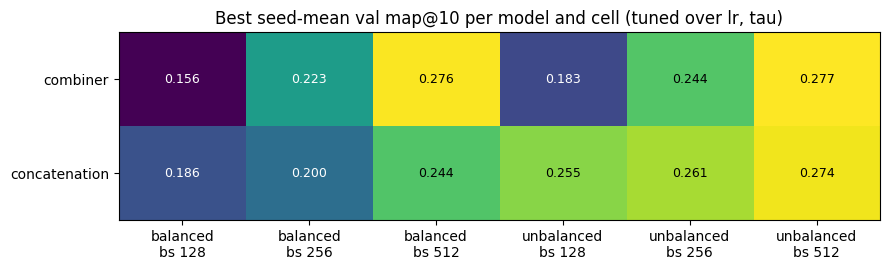

In [33]:
# Shared choice: for each model and (balance, batch size) cell, the best config over lr and tau ("this cell, once tuned")
CELL = ['balance', 'batch_size']
best = configs.loc[configs.groupby(['method'] + CELL)['score'].idxmax()]
table = best.pivot(index='method', columns=CELL, values='score')
display(table.round(4))

import numpy as np

def heatmap(ax, tab, title, fmt='{:.3f}'):
    """tab: DataFrame, annotated heatmap"""
    im = ax.imshow(tab.values, cmap='viridis', aspect='auto')
    ax.set_xticks(range(tab.shape[1]), [f'{c[0]}\nbs {int(c[1])}' if isinstance(c, tuple) else str(c) for c in tab.columns])
    ax.set_yticks(range(tab.shape[0]), [str(i) for i in tab.index])
    for (i, j), v in np.ndenumerate(tab.values):
        ax.text(j, i, fmt.format(v), ha='center', va='center', color='white' if v < tab.values.mean() else 'black', fontsize=9)
    ax.set_title(title)

fig, ax = plt.subplots(figsize=(9, 2.8))
heatmap(ax, table, f'Best seed-mean val {METRIC} per model and cell (tuned over lr, tau)')
plt.tight_layout()
plt.show()

,balance,batch_size,mean,std,within_1std
5,unbalanced,512.0,0.2755,0.0066,True
2,balanced,512.0,0.2600,0.0059,False
4,unbalanced,256.0,0.2527,0.0252,False
3,unbalanced,128.0,0.2189,0.0177,False
1,balanced,256.0,0.2113,0.0043,False
0,balanced,128.0,0.1712,0.0111,False


best cell: unbalanced, bs 512 (0.2755 ± 0.0066)
chosen   : unbalanced, bs 512


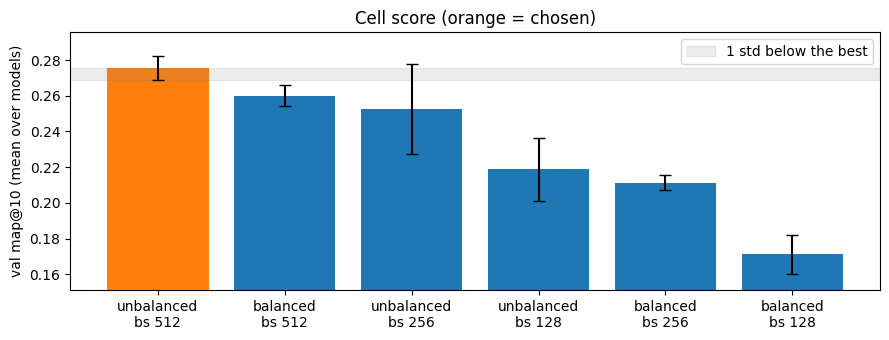

In [34]:
# Choose the cell: score of a cell = mean over the models of their tuned config; per seed, so the std over seeds exists
per_seed = best[CFG].merge(grid, on=CFG)                                          # the 3 seeds of each tuned config
by_seed = per_seed.groupby(CELL + ['seed'])[METRIC].mean()                        # average over the models, one value per seed
cells = by_seed.groupby(CELL).agg(mean='mean', std='std').reset_index().sort_values('mean', ascending=False)

# tie-break: cells within one std of the winner -> the default/cheaper one (unbalanced sampler, then the largest batch size = fewer steps)
winner = cells.iloc[0]
close = cells[cells['mean'] >= winner['mean'] - winner['std']].copy()
close['cost'] = list(zip(close['balance'] == 'balanced', -close['batch_size']))
chosen = close.sort_values('cost').iloc[0]
BALANCE, BATCH_SIZE = chosen['balance'], int(chosen['batch_size'])
display(cells.round(4).assign(within_1std=cells['mean'] >= winner['mean'] - winner['std']))
print(f"best cell: {winner['balance']}, bs {int(winner['batch_size'])} ({winner['mean']:.4f} ± {winner['std']:.4f})")
print(f"chosen   : {BALANCE}, bs {BATCH_SIZE}")

labels = [f"{b}\nbs {int(s)}" for b, s in zip(cells['balance'], cells['batch_size'])]
fig, ax = plt.subplots(figsize=(9, 3.5))
bars = ax.bar(labels, cells['mean'], yerr=cells['std'], capsize=4, color=['tab:orange' if (b, s) == (BALANCE, BATCH_SIZE) else 'tab:blue' for b, s in zip(cells['balance'], cells['batch_size'])])
ax.axhspan(winner['mean'] - winner['std'], winner['mean'], color='gray', alpha=0.15, label='1 std below the best')
ax.set_ylim(cells['mean'].min() - 0.02, cells['mean'].max() + 0.02)
ax.set_ylabel(f'val {METRIC} (mean over models)'); ax.set_title('Cell score (orange = chosen)'); ax.legend()
plt.tight_layout(); plt.show()

,lr,tau,score,std
method,,,,
combiner,0.0001,0.002,0.2767,0.0224
concatenation,0.0001,0.002,0.2743,0.0096


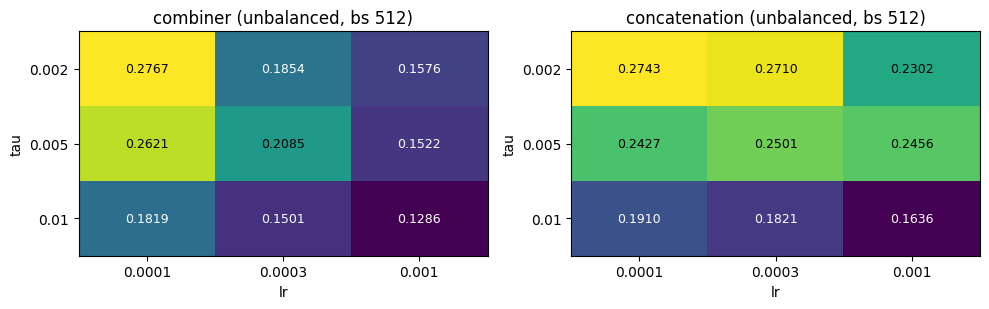

,method,seed,lr,tau,map@10,run
5,combiner,42.0,0.0001,0.002,0.284826,mtsq_combiner_42_tau0.002_lr0.0001_unbalanced_...
11,combiner,43.0,0.0001,0.002,0.293868,mtsq_combiner_43_tau0.002_lr0.0001_unbalanced_...
17,combiner,44.0,0.0001,0.002,0.251423,mtsq_combiner_44_tau0.002_lr0.0001_unbalanced_...
23,concatenation,42.0,0.0001,0.002,0.268251,mtsq_concatenation_42_tau0.002_lr0.0001_unbala...
29,concatenation,43.0,0.0001,0.002,0.269328,mtsq_concatenation_43_tau0.002_lr0.0001_unbala...
35,concatenation,44.0,0.0001,0.002,0.285444,mtsq_concatenation_44_tau0.002_lr0.0001_unbala...


In [35]:
# Choose lr and tau per model, with balance and batch size fixed
final = configs[(configs['balance'] == BALANCE) & (configs['batch_size'] == BATCH_SIZE)]
chosen_cfg = final.loc[final.groupby('method')['score'].idxmax()].set_index('method')[['lr', 'tau', 'score', 'std']]
display(chosen_cfg.round(4))

fig, axes = plt.subplots(1, final['method'].nunique(), figsize=(10, 3.2))
for ax, (model, g) in zip(axes, final.groupby('method')):
    tab = g.pivot(index='tau', columns='lr', values='score')
    heatmap(ax, tab, f'{model} ({BALANCE}, bs {BATCH_SIZE})', fmt='{:.4f}')
    ax.set_xlabel('lr'); ax.set_ylabel('tau')
plt.tight_layout(); plt.show()

# runs of the chosen configs (the 3 seeds), to pick the weights later
chosen_runs = chosen_cfg.reset_index().merge(grid, on=['method', 'lr', 'tau'])
chosen_runs = chosen_runs[(chosen_runs['balance'] == BALANCE) & (chosen_runs['batch_size'] == BATCH_SIZE)]
chosen_runs[['method', 'seed', 'lr', 'tau', METRIC, 'run']].sort_values(['method', 'seed'])

In [36]:
for run in df[df['trained_on'] == 'mtsq']['run']:
    with open(os.path.join(RUNS_FOLDER, run, "settings.json")) as f:
        saved_settings = json.load(f)

    print(saved_settings)

{'experiment_name': 'mtsq_combiner_42_tau0.002_lr0.0001_unbalanced_1028_202558', 'timestamp': '1028_202558', 'model_architecture': 'Combiner(\n  (text_projection_layer): Linear(in_features=512, out_features=256, bias=True)\n  (image_projection_layer): Linear(in_features=512, out_features=256, bias=True)\n  (dropout1): Dropout(p=0.5, inplace=False)\n  (dropout2): Dropout(p=0.5, inplace=False)\n  (combiner_layer): Linear(in_features=512, out_features=128, bias=True)\n  (output_layer): Linear(in_features=128, out_features=512, bias=True)\n  (dropout3): Dropout(p=0.5, inplace=False)\n  (dynamic_scalar): Sequential(\n    (0): Linear(in_features=512, out_features=128, bias=True)\n    (1): ReLU()\n    (2): Dropout(p=0.5, inplace=False)\n    (3): Linear(in_features=128, out_features=1, bias=True)\n    (4): Sigmoid()\n  )\n)', 'model': 'combiner', 'dataset': 'mtsq', 'backbone': 'CLAP', 'seed': 42, 'lr': 0.0001, 'tau': 0.002, 'batch_size': 512, 'balance': False, 'epochs': 100, 'train_dataset': '

# Visualize Test Results

In [37]:
# Test results: 5 rows (baselines + trained models averaged over their seeds), one table per metric, columns = k
test = pd.read_csv(os.path.join(RESULTS_FOLDER, 'mtsq_test_exact.csv'))
test['name'] = test['model'].where(test['method'] == 'baseline', test['method'])     # trained runs: the model name, baselines: their own
ROWS = ['audio_only', 'text_only', 'sum', 'combiner', 'concatenation']
metric_cols = [c for c in test.columns if '@' in c]
grouped = test.groupby('name')[metric_cols]
mean, std = grouped.mean().loc[ROWS], grouped.std().loc[ROWS]                          # over the seeds (std is NaN for the baselines: one run)
final_test = mean.map('{:.4f}'.format).where(std.isna(), mean.map('{:.4f}'.format) + ' ± ' + std.map('{:.4f}'.format))   # "mean ± std"
print(test[test['method'] != 'baseline'].groupby('name')['seed'].count().to_dict(), 'seeds per model')

for metric in ['hit', 'recall', 'mrr', 'map', 'ndcg']:
    print(f'\n{metric}@k (test)')
    display(final_test[[c for c in metric_cols if c.startswith(metric + '@')]].rename_axis('model'))


{'combiner': 3, 'concatenation': 3} seeds per model

hit@k (test)


,hit@1,hit@2,hit@5,hit@10,hit@20,hit@50,hit@100
model,,,,,,,
audio_only,0.1173,0.1645,0.2150,0.2398,0.2610,0.2895,0.3135
text_only,0.0001,0.0001,0.0001,0.0001,0.0002,0.0005,0.0010
sum,0.0210,0.0342,0.0562,0.0747,0.0951,0.1290,0.1604
combiner,0.1861 ± 0.0199,0.2749 ± 0.0249,0.3898 ± 0.0266,0.4545 ± 0.0265,0.5095 ± 0.0256,0.5757 ± 0.0230,0.6235 ± 0.0217
concatenation,0.1762 ± 0.0075,0.2667 ± 0.0093,0.4010 ± 0.0113,0.4823 ± 0.0120,0.5484 ± 0.0130,0.6239 ± 0.0127,0.6748 ± 0.0127



recall@k (test)


,recall@1,recall@2,recall@5,recall@10,recall@20,recall@50,recall@100
model,,,,,,,
audio_only,0.1173,0.1645,0.2150,0.2398,0.2610,0.2895,0.3135
text_only,0.0001,0.0001,0.0001,0.0001,0.0002,0.0005,0.0010
sum,0.0210,0.0342,0.0562,0.0747,0.0951,0.1290,0.1604
combiner,0.1861 ± 0.0199,0.2749 ± 0.0249,0.3898 ± 0.0266,0.4545 ± 0.0265,0.5095 ± 0.0256,0.5757 ± 0.0230,0.6235 ± 0.0217
concatenation,0.1762 ± 0.0075,0.2667 ± 0.0093,0.4010 ± 0.0113,0.4823 ± 0.0120,0.5484 ± 0.0130,0.6239 ± 0.0127,0.6748 ± 0.0127



mrr@k (test)


,mrr@1,mrr@2,mrr@5,mrr@10,mrr@20,mrr@50,mrr@100
model,,,,,,,
audio_only,0.1173,0.1409,0.1550,0.1584,0.1598,0.1607,0.1611
text_only,0.0001,0.0001,0.0001,0.0001,0.0001,0.0001,0.0001
sum,0.0210,0.0276,0.0335,0.0360,0.0374,0.0385,0.0389
combiner,0.1861 ± 0.0199,0.2305 ± 0.0224,0.2623 ± 0.0229,0.2711 ± 0.0229,0.2749 ± 0.0228,0.2771 ± 0.0227,0.2777 ± 0.0227
concatenation,0.1762 ± 0.0075,0.2215 ± 0.0084,0.2584 ± 0.0089,0.2694 ± 0.0090,0.2740 ± 0.0091,0.2765 ± 0.0091,0.2772 ± 0.0091



map@k (test)


,map@1,map@2,map@5,map@10,map@20,map@50,map@100
model,,,,,,,
audio_only,0.1173,0.1409,0.1550,0.1584,0.1598,0.1607,0.1611
text_only,0.0001,0.0001,0.0001,0.0001,0.0001,0.0001,0.0001
sum,0.0210,0.0276,0.0335,0.0360,0.0374,0.0385,0.0389
combiner,0.1861 ± 0.0199,0.2305 ± 0.0224,0.2623 ± 0.0229,0.2711 ± 0.0229,0.2749 ± 0.0228,0.2771 ± 0.0227,0.2777 ± 0.0227
concatenation,0.1762 ± 0.0075,0.2215 ± 0.0084,0.2584 ± 0.0089,0.2694 ± 0.0090,0.2740 ± 0.0091,0.2765 ± 0.0091,0.2772 ± 0.0091



ndcg@k (test)


,ndcg@1,ndcg@2,ndcg@5,ndcg@10,ndcg@20,ndcg@50,ndcg@100
model,,,,,,,
audio_only,0.1173,0.1471,0.1700,0.1781,0.1835,0.1891,0.1930
text_only,0.0001,0.0001,0.0001,0.0001,0.0001,0.0002,0.0002
sum,0.0210,0.0294,0.0392,0.0451,0.0503,0.0570,0.0621
combiner,0.1861 ± 0.0199,0.2421 ± 0.0231,0.2941 ± 0.0238,0.3152 ± 0.0238,0.3291 ± 0.0235,0.3423 ± 0.0230,0.3501 ± 0.0228
concatenation,0.1762 ± 0.0075,0.2333 ± 0.0086,0.2939 ± 0.0095,0.3203 ± 0.0097,0.3371 ± 0.0100,0.3521 ± 0.0099,0.3604 ± 0.0099


In [38]:
# Per subdataset / per modification type: the per-query scores of the test set are recomputed (the csv only has the means)
import torch
from types import SimpleNamespace
from evaluate import build_zero_shot, build_trained
from evaluation_helpers.evaluation_set import EvaluationSet
from evaluation_helpers.retriever import Retriever
from evaluation_helpers.relevance import exact_target, build_relevance
from evaluation_helpers.metrics import score_run

K = 10
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
args = SimpleNamespace(checkpoint='model_best')
eval_set = EvaluationSet('mtsq', 'test', False)
relevant = exact_target(eval_set)

def per_query(method):
    """{'map@10': array [Q], ...}: the score of every test query"""
    top = Retriever(method, eval_set, top_k=K).retrieve()
    is_relevant, num_relevant = build_relevance(top, relevant)
    return {metric: s.numpy() for metric, s in score_run(is_relevant, num_relevant, [K]).items()}

# the baselines and the runs of the test csv (the same ones as above)
builders = [(name, lambda name=name: build_zero_shot(name, args, device)[1]) for name in ROWS[:3]]
builders += [(r['method'], lambda run=r['run']: build_trained(run, args, device)[1]) for _, r in test[test['method'] != 'baseline'].iterrows()]

query_scores = []                                   # (model name, scores of every query)
for name, build in builders:
    method = build()
    query_scores.append((name, per_query(method)))
    del method; torch.cuda.empty_cache()

/home/ldsbrandao/exp/miniconda3/envs/tcc/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading pre-computed cache/audio_evaluation_cache_mtsq_test_no_local.pt cache...
Loading pre-computed cache/text_evaluation_cache_mtsq_test_no_local.pt cache...


In [39]:
# mean ± std over the seeds of the mean score of each group of queries (the baselines have one run: no std)
def by_group(group_column, metric):
    groups = eval_set.triplets_df[group_column].values
    columns = {}
    for name in ROWS:
        runs = [scores[metric] for n, scores in query_scores if n == name]
        per_seed = pd.concat([pd.Series(s).groupby(groups).mean() for s in runs], axis=1)
        per_seed.loc['all'] = [s.mean() for s in runs]
        mean, std = per_seed.mean(axis=1), per_seed.std(axis=1)
        columns[name] = mean.map('{:.4f}'.format) if len(runs) == 1 else mean.map('{:.4f}'.format) + ' ± ' + std.map('{:.4f}'.format)
    table = pd.DataFrame(columns).rename_axis(group_column)
    table.insert(0, 'n_queries', pd.Series(groups).value_counts().reindex(table.index).fillna(len(groups)).astype(int))
    return table.loc[['all'] + sorted(set(table.index) - {'all'})]

for group_column in ['dataset', 'modification']:                    # subdataset, modification type
    for metric in [f'map@{K}', f'recall@{K}', f'ndcg@{K}']:
        print(f'\n{metric} per {group_column} (test)')
        display(by_group(group_column, metric))


map@10 per dataset (test)


,n_queries,audio_only,text_only,sum,combiner,concatenation
dataset,,,,,,
all,128086,0.1584,0.0001,0.0360,0.2711 ± 0.0229,0.2694 ± 0.0090
instrumentation_add,66914,0.0654,0.0001,0.0206,0.2056 ± 0.0138,0.2438 ± 0.0112
instrumentation_remove,21716,0.3820,0.0000,0.0854,0.4733 ± 0.0308,0.4784 ± 0.0142
mood_change,16326,0.0001,0.0001,0.0000,0.0003 ± 0.0002,0.0005 ± 0.0001
velocity,23130,0.3289,0.0000,0.0598,0.4617 ± 0.0584,0.3369 ± 0.0151



recall@10 per dataset (test)


,n_queries,audio_only,text_only,sum,combiner,concatenation
dataset,,,,,,
all,128086,0.2398,0.0001,0.0747,0.4545 ± 0.0265,0.4823 ± 0.0120
instrumentation_add,66914,0.1380,0.0001,0.0502,0.4075 ± 0.0201,0.4847 ± 0.0164
instrumentation_remove,21716,0.4700,0.0000,0.1533,0.6286 ± 0.0335,0.6771 ± 0.0144
mood_change,16326,0.0002,0.0004,0.0000,0.0010 ± 0.0004,0.0015 ± 0.0002
velocity,23130,0.4873,0.0000,0.1243,0.7472 ± 0.0589,0.6317 ± 0.0196



ndcg@10 per dataset (test)


...

,n_queries,audio_only,text_only,sum,combiner,concatenation
modification,,,,,,
all,128086,0.1584,0.0001,0.0360,0.2711 ± 0.0229,0.2694 ± 0.0090
add acoustic guitar,4956,0.0919,0.0000,0.0224,0.0956 ± 0.0085,0.2121 ± 0.0079
add bass,2886,0.1429,0.0000,0.0171,0.2600 ± 0.0504,0.3681 ± 0.0404
add drums,5587,0.5795,0.0000,0.0892,0.6608 ± 0.0520,0.5988 ± 0.0168
add flute,7031,0.0651,0.0000,0.0269,0.2355 ± 0.0024,0.2519 ± 0.0163
add piano,6372,0.0591,0.0000,0.0221,0.2053 ± 0.0086,0.2358 ± 0.0019
add saxophone,7010,0.0791,0.0000,0.0208,0.2027 ± 0.0106,0.2269 ± 0.0034
add violin,8088,0.0752,0.0000,0.0304,0.2288 ± 0.0062,0.2310 ± 0.0094
add vocals,2385,0.0895,0.0000,0.0071,0.2473 ± 0.0246,0.3248 ± 0.0178



recall@10 per modification (test)


,n_queries,audio_only,text_only,sum,combiner,concatenation
modification,,,,,,
all,128086,0.2398,0.0001,0.0747,0.4545 ± 0.0265,0.4823 ± 0.0120
add acoustic guitar,4956,0.1649,0.0000,0.0500,0.2443 ± 0.0163,0.4812 ± 0.0123
add bass,2886,0.2051,0.0000,0.0357,0.3897 ± 0.0631,0.5440 ± 0.0475
add drums,5587,0.6773,0.0000,0.1675,0.8039 ± 0.0442,0.7664 ± 0.0152
add flute,7031,0.1489,0.0001,0.0630,0.4912 ± 0.0034,0.5510 ± 0.0244
add piano,6372,0.1334,0.0000,0.0578,0.4525 ± 0.0154,0.5323 ± 0.0073
add saxophone,7010,0.1690,0.0000,0.0566,0.4628 ± 0.0171,0.5328 ± 0.0053
add violin,8088,0.1574,0.0002,0.0679,0.4715 ± 0.0120,0.5109 ± 0.0154
add vocals,2385,0.1384,0.0000,0.0168,0.3832 ± 0.0330,0.4840 ± 0.0119



ndcg@10 per modification (test)


,n_queries,audio_only,text_only,sum,combiner,concatenation
modification,,,,,,
all,128086,0.1781,0.0001,0.0451,0.3152 ± 0.0238,0.3203 ± 0.0097
add acoustic guitar,4956,0.1097,0.0000,0.0289,0.1306 ± 0.0104,0.2760 ± 0.0090
add bass,2886,0.1582,0.0000,0.0214,0.2911 ± 0.0533,0.4102 ± 0.0421
add drums,5587,0.6036,0.0000,0.1077,0.6957 ± 0.0501,0.6392 ± 0.0162
add flute,7031,0.0853,0.0000,0.0355,0.2968 ± 0.0013,0.3235 ± 0.0181
add piano,6372,0.0770,0.0000,0.0305,0.2643 ± 0.0099,0.3064 ± 0.0030
add saxophone,7010,0.1009,0.0000,0.0292,0.2648 ± 0.0122,0.2998 ± 0.0017
add violin,8088,0.0951,0.0001,0.0393,0.2868 ± 0.0074,0.2976 ± 0.0105
add vocals,2385,0.1013,0.0000,0.0093,0.2797 ± 0.0266,0.3626 ± 0.0162
